# API Models Results Analysis

Pandas/matplotlib analysis of API result files in `results_analysis/apimodels`.

In [10]:

from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.matplotlib-cache'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)
import json, re, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p/'smallmodels').exists() and (p/'apimodels').exists() and (p/'prompt_templates').exists():
            return p.resolve()
    raise FileNotFoundError('results_analysis root not found')

ROOT = find_root()
print('Using', ROOT)

def read_jsonl(path):
    rows = []
    with path.open(encoding='utf-8') as f:
        for line_no, line in enumerate(f, 1):
            if line.strip():
                row = json.loads(line)
                row['_source_file'] = path.name
                row['_line_no'] = line_no
                rows.append(row)
    return rows

def pct_series(s):
    return (100*s).round(1).astype(str) + '%'

def hbar(df, x, y, title, fmt='{:.1%}', color='#3f7fbf', height_per_row=.38, xline=None):
    if df.empty:
        print('No rows')
        return
    fig_h = max(2.4, len(df) * height_per_row)
    fig, ax = plt.subplots(figsize=(9.5, fig_h))
    sns.barplot(data=df, x=x, y=y, ax=ax, color=color)
    if xline is not None:
        ax.axvline(xline, color='0.25', lw=1)
    ax.set_title(title, loc='left', weight='bold')
    ax.set_xlabel(x)
    ax.set_ylabel('')
    xmin, xmax = ax.get_xlim()
    span = xmax - xmin
    for patch, value in zip(ax.patches, df[x]):
        y0 = patch.get_y() + patch.get_height()/2
        if value < 0:
            ax.text(value + span*.015, y0, fmt.format(value), va='center', ha='left', color='white' if abs(value) > span*.08 else 'black', fontsize=9)
        else:
            ax.text(value + span*.015, y0, fmt.format(value), va='center', ha='left', fontsize=9)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

# Load prompt metadata.
templates = {
    'python': pd.read_csv(ROOT/'prompt_templates/prompt_matrix_prompt_template.09.csv'),
    'math': pd.read_csv(ROOT/'prompt_templates/prompt_matrix_prompt_template.09.math.csv'),
}
meta = []
for kind, t in templates.items():
    tmp = t.rename(columns={'ID':'variant_id', 'Tone':'tone', 'Role framing':'role_framing', 'Format':'format'})[['variant_id','tone','role_framing','format']].copy()
    tmp['kind'] = kind
    tmp['variant_id'] = tmp['variant_id'].astype(str)
    tmp['role_binary'] = np.where(tmp['role_framing'].str.lower().eq('no role'), 'no role', 'role')
    meta.append(tmp)
meta = pd.concat(meta, ignore_index=True)

rows = []
for path in sorted((ROOT/'apimodels').glob('*.jsonl')):
    kind = 'python' if path.name.endswith('.python.jsonl') else 'math'
    model = path.name.replace('.python.jsonl','').replace('.math.jsonl','')
    for row in read_jsonl(path):
        row['kind'] = kind
        row['model_slug'] = model
        row['variant_id'] = str(row.get('category_id'))
        row['task_key'] = str(row.get('row_key') or f"{row.get('task_id')}::{row.get('category_id')}")
        usage = row.get('raw_usage') or {}
        row['prompt_tokens'] = usage.get('prompt_tokens', 0)
        row['completion_tokens'] = usage.get('completion_tokens', 0)
        rows.append(row)

df = pd.DataFrame(rows).merge(meta, on=['kind','variant_id'], how='left')
for col in ['duration_seconds','prompt_tokens','completion_tokens']:
    df[col] = pd.to_numeric(df.get(col), errors='coerce').fillna(0)
df['passed'] = df['passed'].astype(bool)
df['empty_response'] = df['response_text'].fillna('').astype(str).str.strip().eq('')
df['api_error'] = df.get('error', '').fillna('').astype(str).str.strip().ne('')
print(f'Rows: {len(df):,}; files: {df._source_file.nunique()}; models: {df.model_slug.nunique()}')


Using /Users/macos/LearningSpace/ue-courses/Thesis/02ScalingPhrase/results_analysis
Rows: 3,600; files: 4; models: 2


## 0. Auto-Generated Key Insights

In [11]:

insights = []
overall = df.groupby('kind').agg(n=('passed','size'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), mean_completion_tokens=('completion_tokens','mean')).reset_index()
for _, r in overall.sort_values('pass_rate', ascending=False).iterrows():
    insights.append(f"**{r.kind}**: {r.pass_rate:.1%} pass rate across {int(r.n):,} runs; median duration {r.median_duration:.2f}s; mean completion tokens {r.mean_completion_tokens:.0f}.")

mk = df.groupby(['kind','model_slug']).agg(pass_rate=('passed','mean'), mean_completion_tokens=('completion_tokens','mean'), median_duration=('duration_seconds','median')).reset_index()
for kind_name, sub in mk.groupby('kind'):
    best = sub.sort_values('pass_rate', ascending=False).iloc[0]
    worst = sub.sort_values('pass_rate', ascending=True).iloc[0]
    insights.append(f"For **{kind_name}**, model choice is decisive: **{best.model_slug}** is highest at {best.pass_rate:.1%}, while **{worst.model_slug}** is lowest at {worst.pass_rate:.1%}.")

deepseek = df[df.model_slug.str.contains('deepseek', case=False, na=False)]
without = df[~df.model_slug.str.contains('deepseek', case=False, na=False)]
if not deepseek.empty and not without.empty:
    for kind_name in sorted(df.kind.unique()):
        a = df[df.kind.eq(kind_name)].passed.mean()
        b = without[without.kind.eq(kind_name)].passed.mean()
        insights.append(f"Removing DeepSeek changes **{kind_name}** from {a:.1%} to {b:.1%}; API-model claims should separate model effect from prompt-framing effect.")

import math as _math
import numpy as _np
from scipy.stats import ttest_ind, mannwhitneyu

def _raw_two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / _math.sqrt(var)
    return _math.erfc(z / _math.sqrt(2))

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
deltas = []
for kind_name, sub in df.groupby('kind'):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in sub.groupby(factor):
            if level == baseline:
                continue
            p_value = _raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            try:
                _, comp_p = ttest_ind(base.completion_tokens.dropna(), items.completion_tokens.dropna(), equal_var=False)
            except Exception:
                comp_p = 1.0
            try:
                _, dur_p = mannwhitneyu(base.duration_seconds.dropna(), items.duration_seconds.dropna(), alternative='two-sided')
            except Exception:
                dur_p = 1.0
            deltas.append({
                'kind': kind_name, 'factor': factor, 'level': level,
                'delta_pp': 100*(items.passed.mean()-base.passed.mean()),
                'completion_delta': items.completion_tokens.mean()-base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.median()-base.duration_seconds.median(),
                'p_value': p_value, 'completion_p': comp_p, 'duration_p': dur_p,
            })
deltas = pd.DataFrame(deltas)
if not deltas.empty:
    display(deltas.sort_values(['kind','factor','level']).reset_index(drop=True))
    strongest = deltas.iloc[deltas.delta_pp.abs().argmax()]
    insights.append(f"The largest raw prompt-factor shift is **{{strongest.kind}} / {{strongest.factor}}={{strongest.level}}** versus baseline: {{strongest.delta_pp:+.1f}} pp pass rate, p={{strongest.p_value:.4f}}, {{strongest.completion_delta:+.0f}} completion tokens (p={{strongest.completion_p:.4f}}), {{strongest.duration_delta:+.2f}}s median duration (p={{strongest.duration_p:.4f}}).")

issues = int((df.empty_response | df.api_error).sum())
if issues:
    insights.append(f"Response-quality warning: {issues} API rows have empty responses or API errors; inspect the response-cleanliness section before making final claims.")
else:
    insights.append("No empty responses or API errors were found in the API result files.")

corr = df[['passed','completion_tokens','duration_seconds']].assign(passed=df.passed.astype(float)).corr(numeric_only=True)
insights.append(f"Efficiency is part of the result: completion-token/pass correlation is {corr.loc['completion_tokens','passed']:+.2f}, and duration/pass correlation is {corr.loc['duration_seconds','passed']:+.2f} across all API runs.")

display(Markdown('\n'.join(f'- {x}' for x in insights)))


,kind,factor,level,delta_pp,completion_delta,duration_delta,p_value,completion_p,duration_p
0,math,format,json,-1.333333,-33.436667,-0.8710,0.643190,0.681682,0.114602
1,math,format,xml,-2.333333,-55.378333,-0.5395,0.417887,0.491193,0.142951
2,math,role_binary,role,-2.777778,82.810000,-0.1375,0.237582,0.199243,0.626518
3,math,tone,aggressive,0.333333,163.296667,-0.5660,0.907825,0.034544,0.950318
4,math,tone,polite,-1.000000,79.613333,-0.4780,0.728565,0.274029,0.737730
5,python,format,json,3.166667,-104.975000,-0.5485,0.244328,0.108055,0.428602
6,python,format,xml,4.833333,-77.471667,-0.8700,0.073686,0.230280,0.328358
7,python,role_binary,role,-1.000000,-10.511111,-0.5535,0.649734,0.837829,0.149575
8,python,tone,aggressive,0.500000,126.521667,0.0830,0.853015,0.056189,0.618513
9,python,tone,polite,0.500000,11.271667,0.4790,0.853015,0.849275,0.959741


- **python**: 67.8% pass rate across 1,800 runs; median duration 13.63s; mean completion tokens 856.
- **math**: 53.3% pass rate across 1,800 runs; median duration 6.26s; mean completion tokens 571.
- For **math**, model choice is decisive: **deepseek-v4-flash** is highest at 82.4%, while **gemini-flash** is lowest at 24.1%.
- For **python**, model choice is decisive: **gemini-flash** is highest at 69.0%, while **deepseek-v4-flash** is lowest at 66.7%.
- Removing DeepSeek changes **math** from 53.3% to 24.1%; API-model claims should separate model effect from prompt-framing effect.
- Removing DeepSeek changes **python** from 67.8% to 69.0%; API-model claims should separate model effect from prompt-framing effect.
- The largest raw prompt-factor shift is **{strongest.kind} / {strongest.factor}={strongest.level}** versus baseline: {strongest.delta_pp:+.1f} pp pass rate, p={strongest.p_value:.4f}, {strongest.completion_delta:+.0f} completion tokens (p={strongest.completion_p:.4f}), {strongest.duration_delta:+.2f}s median duration (p={strongest.duration_p:.4f}).
- No empty responses or API errors were found in the API result files.
- Efficiency is part of the result: completion-token/pass correlation is +0.14, and duration/pass correlation is +0.05 across all API runs.

## 1. Integrity

In [12]:

integrity = (df.groupby('_source_file')
    .agg(rows=('task_key','size'), unique_task_keys=('task_key','nunique'), empty_responses=('empty_response','sum'), api_errors=('api_error','sum'), passed=('passed','sum'))
    .assign(duplicates=lambda x: x['rows']-x['unique_task_keys'])
    .reset_index()
    .sort_values('_source_file'))
display(integrity[['_source_file','rows','unique_task_keys','duplicates','empty_responses','api_errors','passed']])


,_source_file,rows,unique_task_keys,duplicates,empty_responses,api_errors,passed
0,deepseek-v4-flash.math.jsonl,900,900,0,0,0,742
1,deepseek-v4-flash.python.jsonl,900,900,0,0,0,600
2,gemini-flash.math.jsonl,900,900,0,0,0,217
3,gemini-flash.python.jsonl,900,900,0,0,0,621


## 2. Model Performance

,kind,n,passed,pass_rate,median_duration,pass_rate_pct
0,math,1800,959,0.532778,6.2580,53.3%
1,python,1800,1221,0.678333,13.6285,67.8%


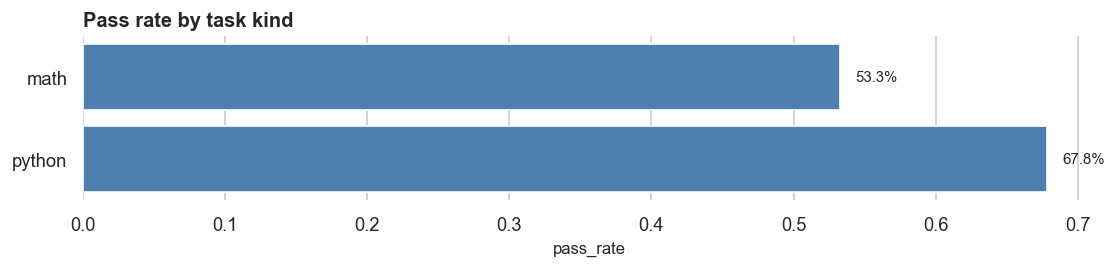

,kind,model_slug,n,passed,pass_rate,median_duration,label
0,math,deepseek-v4-flash,900,742,0.824444,9.4050,math / deepseek-v4-flash
1,math,gemini-flash,900,217,0.241111,3.3975,math / gemini-flash
3,python,gemini-flash,900,621,0.690000,10.2965,python / gemini-flash
2,python,deepseek-v4-flash,900,600,0.666667,16.1170,python / deepseek-v4-flash


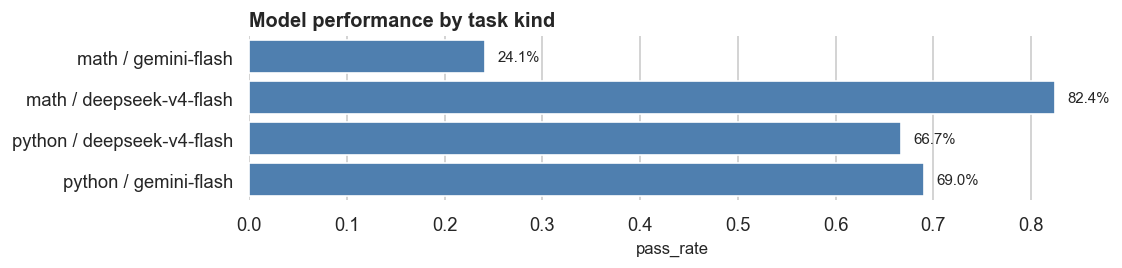

,model_slug,n,passed,pass_rate,median_duration
0,deepseek-v4-flash,1800,1342,0.745556,13.453
1,gemini-flash,1800,838,0.465556,6.577


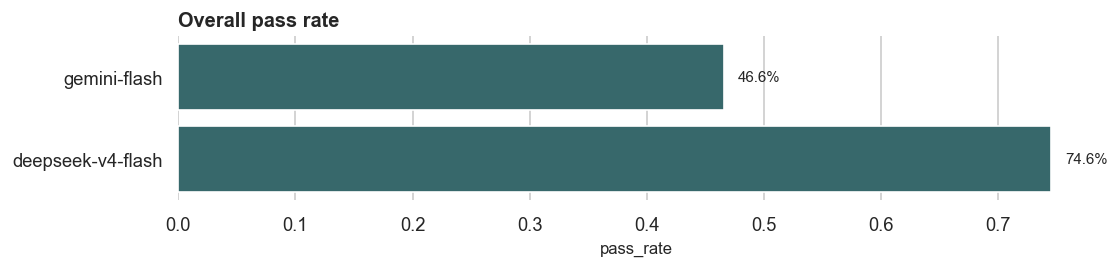

In [13]:

kind = df.groupby('kind').agg(n=('passed','size'), passed=('passed','sum'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median')).reset_index()
display(kind.assign(pass_rate_pct=pct_series(kind.pass_rate)))
hbar(kind.sort_values('pass_rate'), 'pass_rate', 'kind', 'Pass rate by task kind')

mk = df.groupby(['kind','model_slug']).agg(n=('passed','size'), passed=('passed','sum'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median')).reset_index()
mk['label'] = mk['kind'] + ' / ' + mk['model_slug']
display(mk.sort_values(['kind','pass_rate'], ascending=[True,False]))
hbar(mk.sort_values(['kind','pass_rate'], ascending=[True,True]), 'pass_rate', 'label', 'Model performance by task kind', height_per_row=.42)

overall = df.groupby('model_slug').agg(n=('passed','size'), passed=('passed','sum'), pass_rate=('passed','mean'), median_duration=('duration_seconds','median')).reset_index()
display(overall.sort_values('pass_rate', ascending=False))
hbar(overall.sort_values('pass_rate'), 'pass_rate', 'model_slug', 'Overall pass rate', color='#2f6f73', height_per_row=.5)


## 3. Pairwise Common-Task Comparison

In [14]:

records = []
models = sorted(df.model_slug.unique())
for kind_name, sub in df.groupby('kind'):
    for i, a in enumerate(models):
        for b in models[i+1:]:
            left = sub[sub.model_slug.eq(a)].set_index('task_key')['passed']
            right = sub[sub.model_slug.eq(b)].set_index('task_key')['passed']
            common = left.index.intersection(right.index)
            records.append({
                'kind': kind_name, 'model_a': a, 'model_b': b, 'common_tasks': len(common),
                'both_pass': int((left[common] & right[common]).sum()),
                'a_only_pass': int((left[common] & ~right[common]).sum()),
                'b_only_pass': int((~left[common] & right[common]).sum()),
                'both_fail': int((~left[common] & ~right[common]).sum()),
            })
pairwise = pd.DataFrame(records)
display(pairwise)


,kind,model_a,model_b,common_tasks,both_pass,a_only_pass,b_only_pass,both_fail
0,math,deepseek-v4-flash,gemini-flash,900,200,542,17,141
1,python,deepseek-v4-flash,gemini-flash,900,500,100,121,179


## 4. Runtime And Tokens

,kind,model_slug,pass_rate,median_duration,mean_duration,mean_prompt_tokens,mean_completion_tokens,label
0,math,deepseek-v4-flash,0.824444,9.4050,18.461962,161.077778,1127.236667,math / deepseek-v4-flash
1,math,gemini-flash,0.241111,3.3975,10.204542,169.320000,14.766667,math / gemini-flash
2,python,deepseek-v4-flash,0.666667,16.1170,21.786891,224.791111,1352.435556,python / deepseek-v4-flash
3,python,gemini-flash,0.690000,10.2965,17.967658,241.513333,359.300000,python / gemini-flash


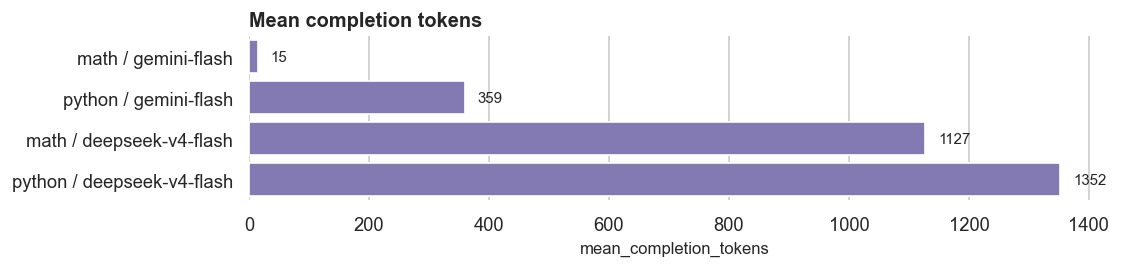

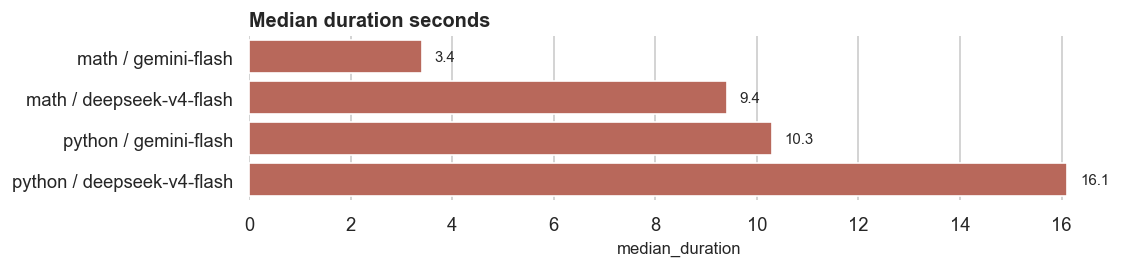

In [15]:

behavior = df.groupby(['kind','model_slug']).agg(
    pass_rate=('passed','mean'), median_duration=('duration_seconds','median'), mean_duration=('duration_seconds','mean'),
    mean_prompt_tokens=('prompt_tokens','mean'), mean_completion_tokens=('completion_tokens','mean')
).reset_index()
behavior['label'] = behavior['kind'] + ' / ' + behavior['model_slug']
display(behavior.sort_values(['kind','mean_completion_tokens'], ascending=[True,False]))
hbar(behavior.sort_values('mean_completion_tokens'), 'mean_completion_tokens', 'label', 'Mean completion tokens', fmt='{:.0f}', color='#7c6fbd', height_per_row=.42)
hbar(behavior.sort_values('median_duration'), 'median_duration', 'label', 'Median duration seconds', fmt='{:.1f}', color='#c75d4c', height_per_row=.42)


## 5. Prompt Factor Deltas

,kind,factor,level,baseline,baseline_n,n,baseline_pass_rate,pass_rate,delta_pass_rate_pp,p_value,delta_completion_tokens,delta_duration_seconds,label
3,math,format,json,plaintext,600,600,0.545000,0.531667,-1.333333,0.643190,-33.436667,-1.960827,math / format=json
4,math,format,xml,plaintext,600,600,0.545000,0.521667,-2.333333,0.417887,-55.378333,-1.705222,math / format=xml
2,math,role_binary,role,no role,900,900,0.546667,0.518889,-2.777778,0.237582,82.810000,0.473353,math / role_binary=role
0,math,tone,aggressive,neutral,600,600,0.535000,0.538333,0.333333,0.907825,163.296667,0.952783,math / tone=aggressive
1,math,tone,polite,neutral,600,600,0.535000,0.525000,-1.000000,0.728565,79.613333,-0.402102,math / tone=polite
8,python,format,json,plaintext,600,600,0.651667,0.683333,3.166667,0.244328,-104.975000,-1.554482,python / format=json
9,python,format,xml,plaintext,600,600,0.651667,0.700000,4.833333,0.073686,-77.471667,-1.115480,python / format=xml
7,python,role_binary,role,no role,900,900,0.683333,0.673333,-1.000000,0.649734,-10.511111,-2.068220,python / role_binary=role
5,python,tone,aggressive,neutral,600,600,0.675000,0.680000,0.500000,0.853015,126.521667,0.722845,python / tone=aggressive
6,python,tone,polite,neutral,600,600,0.675000,0.680000,0.500000,0.853015,11.271667,1.028883,python / tone=polite


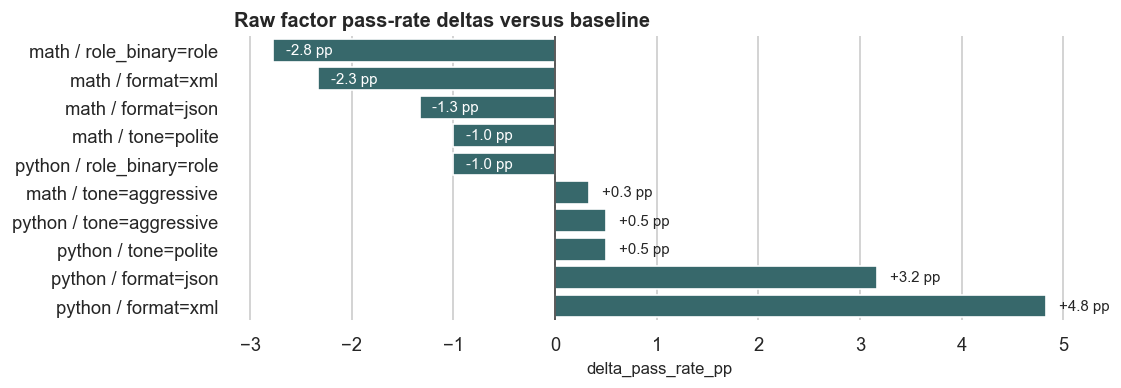

In [16]:

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}

def raw_two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / math.sqrt(var)
    return math.erfc(z / math.sqrt(2))

records = []
for kind_name, sub in df.groupby('kind'):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        for level, items in sub.groupby(factor):
            if level == baseline or base.empty:
                continue
            p_value = raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            records.append({
                'kind': kind_name, 'factor': factor, 'level': level, 'baseline': baseline,
                'baseline_n': len(base), 'n': len(items),
                'baseline_pass_rate': base.passed.mean(), 'pass_rate': items.passed.mean(),
                'delta_pass_rate_pp': 100*(items.passed.mean() - base.passed.mean()),
                'p_value': p_value,
                'delta_completion_tokens': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'delta_duration_seconds': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
contrasts = pd.DataFrame(records)
contrasts['label'] = contrasts['kind'] + ' / ' + contrasts['factor'] + '=' + contrasts['level']
display(contrasts.sort_values(['kind','factor','level']))
hbar(contrasts.sort_values('delta_pass_rate_pp'), 'delta_pass_rate_pp', 'label', 'Raw factor pass-rate deltas versus baseline', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.34)


## 6. Category Sensitivity

,kind,model_slug,category_id,n,pass_rate
3,math,deepseek-v4-flash,12,50,0.70
15,math,deepseek-v4-flash,7,50,0.72
9,math,deepseek-v4-flash,18,50,0.76
13,math,deepseek-v4-flash,5,50,0.78
6,math,deepseek-v4-flash,15,50,0.80
11,math,deepseek-v4-flash,3,50,0.80
20,math,gemini-flash,11,50,0.20
26,math,gemini-flash,17,50,0.20
28,math,gemini-flash,2,50,0.20
31,math,gemini-flash,5,50,0.20


,kind,category_id,min_pass_rate,max_pass_rate,mean_pass_rate,range_pass_rate
1,math,10,0.22,0.90,0.56,0.68
16,math,8,0.24,0.90,0.57,0.66
2,math,11,0.20,0.86,0.53,0.66
10,math,2,0.20,0.86,0.53,0.66
17,math,9,0.22,0.84,0.53,0.62
4,math,13,0.28,0.90,0.59,0.62
8,math,17,0.20,0.82,0.51,0.62
5,math,14,0.26,0.86,0.56,0.60
7,math,16,0.22,0.82,0.52,0.60
14,math,6,0.24,0.84,0.54,0.60


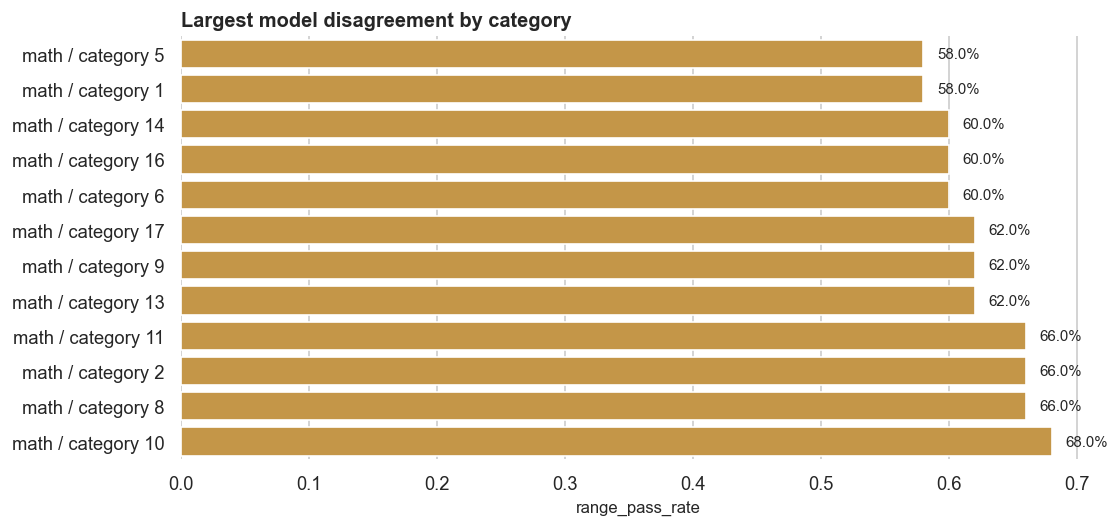

In [17]:

cat = df.groupby(['kind','model_slug','category_id']).agg(n=('passed','size'), pass_rate=('passed','mean')).reset_index()
display(cat.sort_values(['kind','model_slug','pass_rate']).groupby(['kind','model_slug']).head(6))
spread = cat.groupby(['kind','category_id']).agg(min_pass_rate=('pass_rate','min'), max_pass_rate=('pass_rate','max'), mean_pass_rate=('pass_rate','mean')).assign(range_pass_rate=lambda x: x.max_pass_rate-x.min_pass_rate).reset_index().sort_values('range_pass_rate', ascending=False)
display(spread.head(20))
spread['label'] = spread['kind'] + ' / category ' + spread['category_id'].astype(str)
hbar(spread.head(12).sort_values('range_pass_rate'), 'range_pass_rate', 'label', 'Largest model disagreement by category', color='#d89b34', height_per_row=.38)


## 7. Prompt Framing Significance

In [18]:

def two_prop_p(success_a, total_a, success_b, total_b):
    if total_a == 0 or total_b == 0:
        return 1.0
    pooled = (success_a + success_b) / (total_a + total_b)
    var = pooled * (1 - pooled) * (1/total_a + 1/total_b)
    if var <= 0:
        return 1.0
    z = abs((success_b/total_b) - (success_a/total_a)) / np.sqrt(var)
    return math.erfc(z / np.sqrt(2))

def sign_p(pos, neg):
    n = pos + neg
    if n == 0:
        return 1.0
    k = min(pos, neg)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k+1)) / (2**n))

sig = []
for (kind_name, model), sub in df.groupby(['kind','model_slug']):
    for factor in ['tone','role_binary','format']:
        levels = sorted(sub[factor].dropna().unique())
        for i, a in enumerate(levels):
            for b in levels[i+1:]:
                A, B = sub[sub[factor].eq(a)], sub[sub[factor].eq(b)]
                paired = []
                for _, unit in sub.groupby('task_id'):
                    if a in set(unit[factor]) and b in set(unit[factor]):
                        paired.append(unit[unit[factor].eq(b)].passed.mean() - unit[unit[factor].eq(a)].passed.mean())
                paired = np.array(paired)
                pos = int((paired > 0).sum()); neg = int((paired < 0).sum())
                sig.append({'kind':kind_name, 'model_slug':model, 'factor':factor, 'level_a':a, 'level_b':b,
                            'n_a':len(A), 'pass_rate_a':A.passed.mean(), 'n_b':len(B), 'pass_rate_b':B.passed.mean(),
                            'delta_b_minus_a_pp':100*(B.passed.mean()-A.passed.mean()),
                            'pooled_p':two_prop_p(A.passed.sum(), len(A), B.passed.sum(), len(B)),
                            'paired_bases':len(paired), 'paired_mean_delta_pp':100*paired.mean() if len(paired) else 0,
                            'paired_positive_bases':pos, 'paired_negative_bases':neg, 'paired_sign_p':sign_p(pos, neg)})
sig = pd.DataFrame(sig)
sig['pooled_significant_0_05'] = sig.pooled_p < 0.05
sig['paired_significant_0_05'] = sig.paired_sign_p < 0.05
display(sig.sort_values(['pooled_p','paired_sign_p']).head(20))
print('Significant pooled contrasts:', int(sig.pooled_significant_0_05.sum()))
print('Significant paired sign-test contrasts:', int(sig.paired_significant_0_05.sum()))


,kind,model_slug,factor,level_a,level_b,n_a,pass_rate_a,n_b,pass_rate_b,delta_b_minus_a_pp,pooled_p,paired_bases,paired_mean_delta_pp,paired_positive_bases,paired_negative_bases,paired_sign_p,pooled_significant_0_05,paired_significant_0_05
20,python,deepseek-v4-flash,format,plaintext,xml,300,0.626667,300,0.696667,7.000000,0.069990,50,7.000000,21,8,0.024120,False,True
5,math,deepseek-v4-flash,format,json,xml,300,0.846667,300,0.790000,-5.666667,0.071862,50,-5.666667,10,20,0.098737,False,False
6,math,deepseek-v4-flash,format,plaintext,xml,300,0.836667,300,0.790000,-4.666667,0.142418,50,-4.666667,14,19,0.486850,False,False
18,python,deepseek-v4-flash,format,json,plaintext,300,0.676667,300,0.626667,-5.000000,0.198687,50,-5.000000,10,18,0.184933,False,False
3,math,deepseek-v4-flash,role_binary,no role,role,450,0.840000,450,0.808889,-3.111111,0.219956,50,-3.111111,16,21,0.511376,False,False
11,math,gemini-flash,format,json,plaintext,300,0.216667,300,0.253333,3.666667,0.289537,50,3.666667,7,1,0.070312,False,False
12,math,gemini-flash,format,json,xml,300,0.216667,300,0.253333,3.666667,0.289537,50,3.666667,6,2,0.289062,False,False
14,python,deepseek-v4-flash,tone,aggressive,neutral,300,0.680000,300,0.643333,-3.666667,0.342555,50,-3.666667,11,18,0.264931,False,False
16,python,deepseek-v4-flash,tone,neutral,polite,300,0.643333,300,0.676667,3.333333,0.388791,50,3.333333,21,9,0.042774,False,True
10,math,gemini-flash,role_binary,no role,role,450,0.253333,450,0.228889,-2.444444,0.391344,50,-2.444444,2,6,0.289062,False,False


Significant pooled contrasts: 0
Significant paired sign-test contrasts: 2


## 8. Response Cleanliness And Error Modes

In [19]:

def has_leading_zero(row):
    er = row.get('eval_result') or {}
    text = str(er.get('stderr') or '') + ' ' + ' '.join(map(str, er.get('errors') or []))
    return 'leading zeros in decimal integer literals' in text

df['leading_zero_eval_error'] = df.apply(has_leading_zero, axis=1)
issue = df.assign(response_issue=df.empty_response | df.api_error | df.leading_zero_eval_error)
issue_summary = issue.groupby(['kind','model_slug']).agg(n=('passed','size'), empty=('empty_response','sum'), api_error=('api_error','sum'), leading_zero=('leading_zero_eval_error','sum'), response_issue_rate=('response_issue','mean')).reset_index()
display(issue_summary)
if issue_summary[['empty','api_error','leading_zero']].sum().sum() == 0:
    display(Markdown('No unresolved response issues remain.'))


,kind,model_slug,n,empty,api_error,leading_zero,response_issue_rate
0,math,deepseek-v4-flash,900,0,0,0,0.0
1,math,gemini-flash,900,0,0,0,0.0
2,python,deepseek-v4-flash,900,0,0,0,0.0
3,python,gemini-flash,900,0,0,0,0.0


No unresolved response issues remain.

## 9. Paired Prompt-Factor Contrasts

,kind,factor,baseline,level,paired_units,mean_pass_delta_pp,positive_units,negative_units,mean_completion_delta,mean_duration_delta,label
0,math,format,plaintext,json,100,-1.333333,15,20,-33.436667,-1.960827,math / format=json
1,math,format,plaintext,xml,100,-2.333333,18,22,-55.378333,-1.705222,math / format=xml
2,math,role_binary,no role,role,100,-2.777778,18,27,82.810000,0.473353,math / role_binary=role
3,math,tone,neutral,aggressive,100,0.333333,16,15,163.296667,0.952783,math / tone=aggressive
4,math,tone,neutral,polite,100,-1.000000,16,19,79.613333,-0.402102,math / tone=polite
5,python,format,plaintext,json,100,3.166667,27,17,-104.975000,-1.554482,python / format=json
6,python,format,plaintext,xml,100,4.833333,30,14,-77.471667,-1.115480,python / format=xml
7,python,role_binary,no role,role,100,-1.000000,23,27,-10.511111,-2.068220,python / role_binary=role
8,python,tone,neutral,aggressive,100,0.500000,27,20,126.521667,0.722845,python / tone=aggressive
9,python,tone,neutral,polite,100,0.500000,30,19,11.271667,1.028883,python / tone=polite


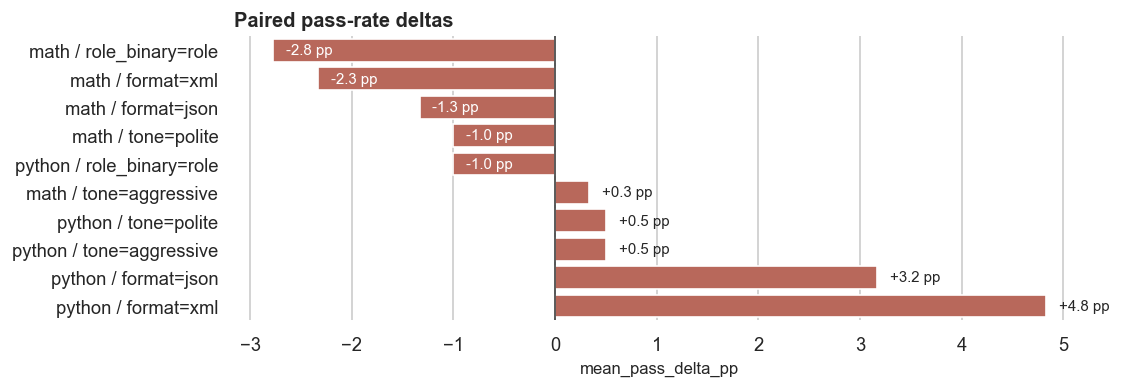

In [20]:

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
paired_records = []
for (kind_name, model, base_task), unit in df.groupby(['kind','model_slug','task_id']):
    for factor, baseline in baselines.items():
        base = unit[unit[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in unit.groupby(factor):
            if level == baseline:
                continue
            paired_records.append({
                'kind': kind_name, 'model_slug': model, 'task_id': base_task,
                'factor': factor, 'baseline': baseline, 'level': level,
                'pass_delta': items.passed.mean() - base.passed.mean(),
                'completion_delta': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
paired_unit = pd.DataFrame(paired_records)
paired = (paired_unit.groupby(['kind','factor','baseline','level'])
    .agg(paired_units=('pass_delta','size'), mean_pass_delta_pp=('pass_delta', lambda s: 100*s.mean()),
         positive_units=('pass_delta', lambda s: int((s>0).sum())), negative_units=('pass_delta', lambda s: int((s<0).sum())),
         mean_completion_delta=('completion_delta','mean'), mean_duration_delta=('duration_delta','mean'))
    .reset_index())
paired['label'] = paired['kind'] + ' / ' + paired['factor'] + '=' + paired['level']
display(paired.sort_values(['kind','factor','level']))
hbar(paired.sort_values('mean_pass_delta_pp'), 'mean_pass_delta_pp', 'label', 'Paired pass-rate deltas', fmt='{:+.1f} pp', color='#c75d4c', xline=0, height_per_row=.34)


## 10. Model-Specific Heterogeneity

,kind,factor,level,min_delta_pp,max_delta_pp,mean_delta_pp,range_delta_pp,label
8,python,tone,aggressive,-2.666667,3.666667,0.500000,6.333333,python / tone=aggressive
9,python,tone,polite,-2.333333,3.333333,0.500000,5.666667,python / tone=polite
0,math,format,json,-3.666667,1.000000,-1.333333,4.666667,math / format=json
1,math,format,xml,-4.666667,0.000000,-2.333333,4.666667,math / format=xml
6,python,format,xml,2.666667,7.000000,4.833333,4.333333,python / format=xml
5,python,format,json,1.333333,5.000000,3.166667,3.666667,python / format=json
7,python,role_binary,role,-2.000000,0.000000,-1.000000,2.000000,python / role_binary=role
3,math,tone,aggressive,0.000000,0.666667,0.333333,0.666667,math / tone=aggressive
2,math,role_binary,role,-3.111111,-2.444444,-2.777778,0.666667,math / role_binary=role
4,math,tone,polite,-1.333333,-0.666667,-1.000000,0.666667,math / tone=polite


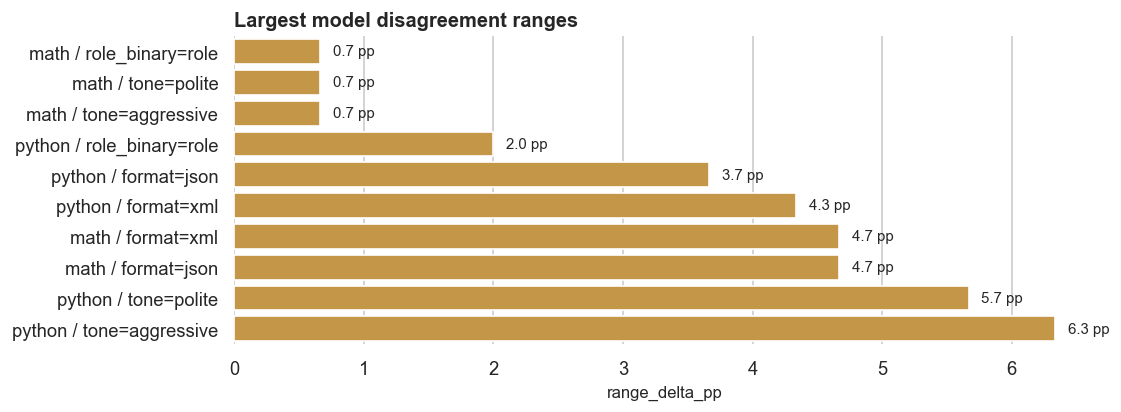

,kind,model_slug,factor,level,delta_pp,n
3,math,deepseek-v4-flash,format,json,1.000000,300
8,math,gemini-flash,format,json,-3.666667,300
9,math,gemini-flash,format,xml,0.000000,300
4,math,deepseek-v4-flash,format,xml,-4.666667,300
7,math,gemini-flash,role_binary,role,-2.444444,450
2,math,deepseek-v4-flash,role_binary,role,-3.111111,450
5,math,gemini-flash,tone,aggressive,0.666667,300
0,math,deepseek-v4-flash,tone,aggressive,0.000000,300
1,math,deepseek-v4-flash,tone,polite,-0.666667,300
6,math,gemini-flash,tone,polite,-1.333333,300


In [21]:

baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
model_contrasts = []
for (kind_name, model), sub in df.groupby(['kind','model_slug']):
    for factor, baseline in baselines.items():
        base = sub[sub[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in sub.groupby(factor):
            if level == baseline:
                continue
            model_contrasts.append({'kind':kind_name, 'model_slug':model, 'factor':factor, 'level':level, 'delta_pp':100*(items.passed.mean()-base.passed.mean()), 'n':len(items)})
model_contrasts = pd.DataFrame(model_contrasts)
hetero = (model_contrasts.groupby(['kind','factor','level'])
    .agg(min_delta_pp=('delta_pp','min'), max_delta_pp=('delta_pp','max'), mean_delta_pp=('delta_pp','mean'))
    .assign(range_delta_pp=lambda x: x.max_delta_pp - x.min_delta_pp)
    .reset_index().sort_values('range_delta_pp', ascending=False))
hetero['label'] = hetero['kind'] + ' / ' + hetero['factor'] + '=' + hetero['level']
display(hetero)
hbar(hetero.head(12).sort_values('range_delta_pp'), 'range_delta_pp', 'label', 'Largest model disagreement ranges', fmt='{:.1f} pp', color='#d89b34', height_per_row=.36)
display(model_contrasts.sort_values(['kind','factor','level','delta_pp'], ascending=[True,True,True,False]).head(30))


## 11. Math-Versus-Python Factor Differences

kind,model_slug,factor,level,math_delta_pp,python_delta_pp,math_minus_python_delta_pp,label
1,deepseek-v4-flash,format,xml,-4.666667,7.000000,-11.666667,deepseek-v4-flash / format=xml
5,gemini-flash,format,json,-3.666667,1.333333,-5.000000,gemini-flash / format=json
4,deepseek-v4-flash,tone,polite,-0.666667,3.333333,-4.000000,deepseek-v4-flash / tone=polite
0,deepseek-v4-flash,format,json,1.000000,5.000000,-4.000000,deepseek-v4-flash / format=json
3,deepseek-v4-flash,tone,aggressive,0.000000,3.666667,-3.666667,deepseek-v4-flash / tone=aggressive
8,gemini-flash,tone,aggressive,0.666667,-2.666667,3.333333,gemini-flash / tone=aggressive
2,deepseek-v4-flash,role_binary,role,-3.111111,0.000000,-3.111111,deepseek-v4-flash / role_binary=role
6,gemini-flash,format,xml,0.000000,2.666667,-2.666667,gemini-flash / format=xml
9,gemini-flash,tone,polite,-1.333333,-2.333333,1.000000,gemini-flash / tone=polite
7,gemini-flash,role_binary,role,-2.444444,-2.000000,-0.444444,gemini-flash / role_binary=role


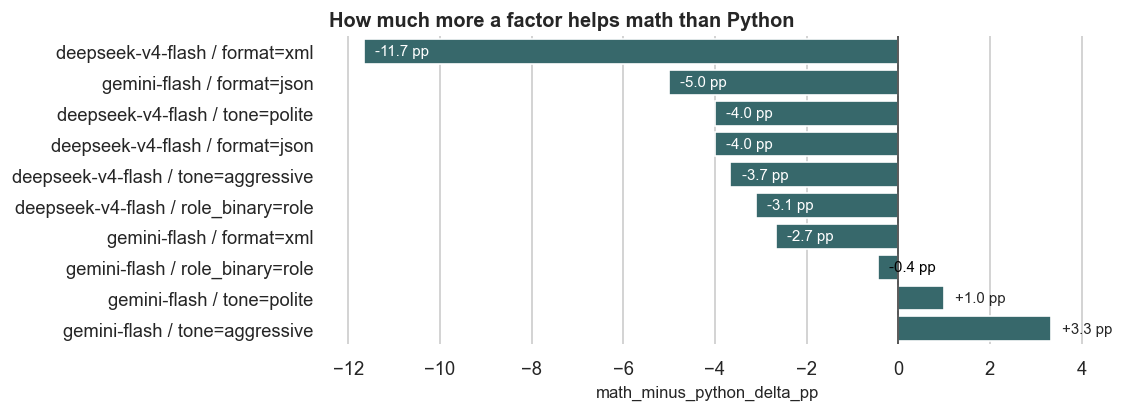

In [22]:

wide = model_contrasts.pivot_table(index=['model_slug','factor','level'], columns='kind', values='delta_pp').reset_index()
if {'math','python'}.issubset(wide.columns):
    wide['math_minus_python_delta_pp'] = wide['math'] - wide['python']
    wide = wide.sort_values('math_minus_python_delta_pp', key=lambda s: s.abs(), ascending=False)
    wide['label'] = wide['model_slug'] + ' / ' + wide['factor'] + '=' + wide['level']
    display(wide.rename(columns={'python':'python_delta_pp','math':'math_delta_pp'}).head(30))
    hbar(wide.head(15).sort_values('math_minus_python_delta_pp'), 'math_minus_python_delta_pp', 'label', 'How much more a factor helps math than Python', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.36)
else:
    print('Need both math and python rows for this comparison')


## 12. Dominant-Model Sensitivity

,dataset,kind,n,passed,pass_rate,mean_completion_tokens,median_duration_seconds
0,full,math,1800,959,0.532778,571.001667,6.2580
1,full,python,1800,1221,0.678333,855.867778,13.6285
2,without_deepseek,math,900,217,0.241111,14.766667,3.3975
3,without_deepseek,python,900,621,0.690000,359.300000,10.2965


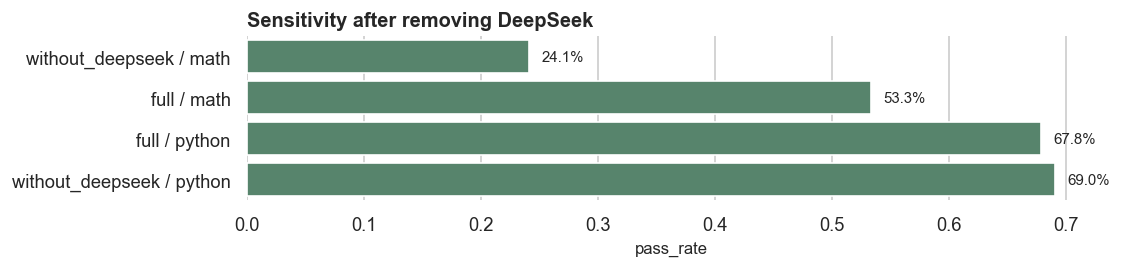

In [23]:

without_deepseek = df[~df.model_slug.str.contains('deepseek', case=False, na=False)].copy()
compare = []
for label, data in [('full', df), ('without_deepseek', without_deepseek)]:
    for kind_name, items in data.groupby('kind'):
        compare.append({'dataset':label, 'kind':kind_name, 'n':len(items), 'passed':items.passed.sum(), 'pass_rate':items.passed.mean(), 'mean_completion_tokens':items.completion_tokens.mean(), 'median_duration_seconds':items.duration_seconds.median()})
compare = pd.DataFrame(compare)
display(compare)
plot = compare.assign(label=compare.dataset + ' / ' + compare.kind).sort_values('pass_rate')
hbar(plot, 'pass_rate', 'label', 'Sensitivity after removing DeepSeek', color='#4f8c6b')


## 13. Hardest/Easiest Tasks And Any-Variant Solved

**Hardest base tasks**

,kind,task_id,n,pass_rate,models_solved
21,math,math_022,36,0.111111,1.0
43,math,math_044,36,0.166667,1.0
46,math,math_047,36,0.222222,1.0
2,math,math_003,36,0.250000,1.0
44,math,math_045,36,0.250000,1.0
36,math,math_037,36,0.277778,1.0
45,math,math_046,36,0.305556,1.0
47,math,math_048,36,0.305556,1.0
48,math,math_049,36,0.305556,1.0
17,math,math_018,36,0.333333,1.0


**Easiest base tasks**

,kind,task_id,n,pass_rate,models_solved
26,math,math_027,36,1.000000,2.0
28,math,math_029,36,1.000000,2.0
24,math,math_025,36,0.972222,2.0
31,math,math_032,36,0.972222,2.0
32,math,math_033,36,0.972222,2.0
33,math,math_034,36,0.972222,2.0
22,math,math_023,36,0.944444,2.0
27,math,math_028,36,0.916667,2.0
30,math,math_031,36,0.888889,2.0
34,math,math_035,36,0.888889,2.0


,kind,model_slug,any_variant_solved_rate,label
0,math,deepseek-v4-flash,1.00,math / deepseek-v4-flash
1,math,gemini-flash,0.36,math / gemini-flash
2,python,deepseek-v4-flash,0.90,python / deepseek-v4-flash
3,python,gemini-flash,0.86,python / gemini-flash


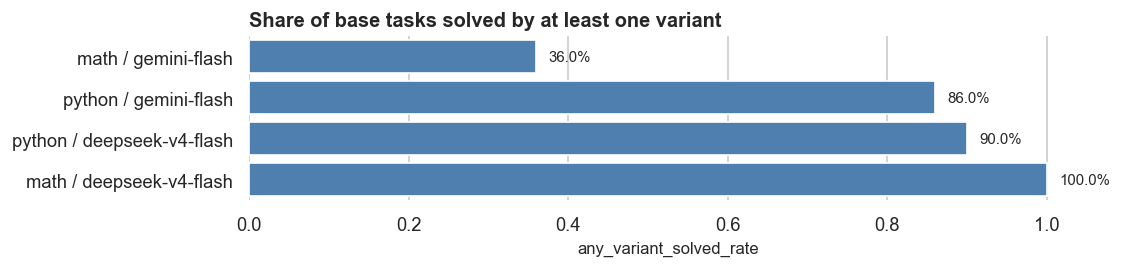

In [24]:

base = df.groupby(['kind','task_id']).agg(n=('passed','size'), pass_rate=('passed','mean')).reset_index()
models_solved = df[df.passed].groupby(['kind','task_id'])['model_slug'].nunique().rename('models_solved')
base = base.merge(models_solved, on=['kind','task_id'], how='left').fillna({'models_solved':0})
display(Markdown('**Hardest base tasks**'))
display(base.sort_values(['kind','pass_rate','models_solved']).groupby('kind').head(10))
display(Markdown('**Easiest base tasks**'))
display(base.sort_values(['kind','pass_rate','models_solved'], ascending=[True,False,False]).groupby('kind').head(10))
any_variant = (df.groupby(['kind','model_slug','task_id'])['passed'].any().reset_index()
    .groupby(['kind','model_slug'])['passed'].mean().reset_index(name='any_variant_solved_rate'))
any_variant['label'] = any_variant['kind'] + ' / ' + any_variant['model_slug']
display(any_variant.sort_values(['kind','any_variant_solved_rate'], ascending=[True,False]))
hbar(any_variant.sort_values('any_variant_solved_rate'), 'any_variant_solved_rate', 'label', 'Share of base tasks solved by at least one variant', color='#3f7fbf', height_per_row=.38)


## 14. Token/Duration Correlations

In [25]:

corr_rows = []
for (kind_name, model), sub in df.groupby(['kind','model_slug']):
    if sub.passed.nunique() > 1:
        corr_rows.append({'kind':kind_name, 'model_slug':model, 'completion_vs_pass_corr':sub.completion_tokens.corr(sub.passed.astype(float)), 'duration_vs_pass_corr':sub.duration_seconds.corr(sub.passed.astype(float)), 'prompt_tokens_vs_pass_corr':sub.prompt_tokens.corr(sub.passed.astype(float))})
corr = pd.DataFrame(corr_rows)
display(corr.sort_values(['kind','model_slug']))


,kind,model_slug,completion_vs_pass_corr,duration_vs_pass_corr,prompt_tokens_vs_pass_corr
0,math,deepseek-v4-flash,0.043806,0.071330,-0.141961
1,math,gemini-flash,-0.046067,0.070525,-0.175896
2,python,deepseek-v4-flash,-0.048577,-0.169358,-0.142278
3,python,gemini-flash,-0.238422,-0.083808,-0.194864


## 15. Behavioral Metrics From Deep Analysis

,kind,tone,passed,tests_fraction,completion_tokens,duration_seconds,response_chars,response_lines,extraction_failed,runtime_failure
0,math,aggressive,0.538333,0.538333,653.328333,15.102475,209.386667,4.750000,0.0,0.461667
1,math,neutral,0.535000,0.535000,490.031667,14.149692,183.733333,5.080000,0.0,0.465000
2,math,polite,0.525000,0.525000,569.645000,13.747590,138.603333,3.866667,0.0,0.475000
3,python,aggressive,0.680000,NaN,936.458333,20.016210,1131.216667,34.335000,0.0,0.320000
4,python,neutral,0.675000,NaN,809.936667,19.293365,999.626667,30.621667,0.0,0.325000
5,python,polite,0.680000,NaN,821.208333,20.322248,1115.615000,34.003333,0.0,0.320000


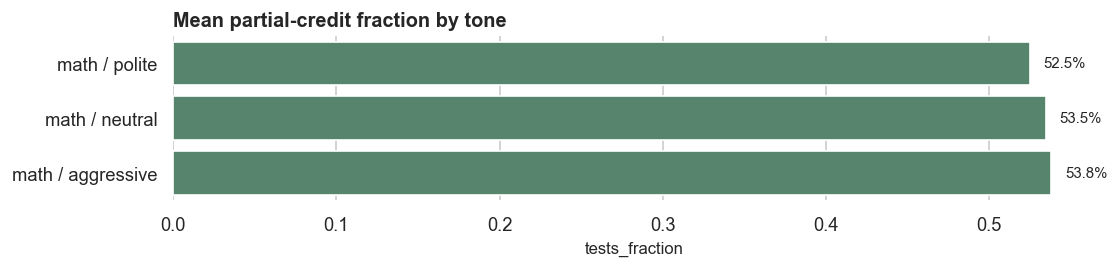

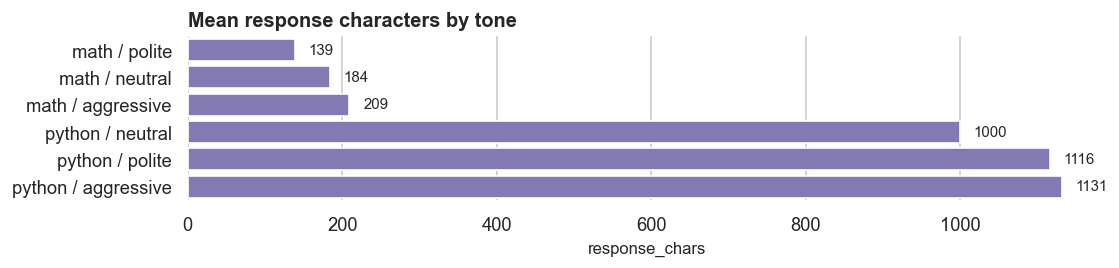

In [26]:

def safe_len(value):
    if isinstance(value, str):
        return len(value)
    if pd.isna(value):
        return 0
    return len(str(value))

def count_lines(value):
    if not isinstance(value, str) or not value.strip():
        return 0
    return len(value.splitlines())

def eval_number(row, key):
    er = row.get('eval_result') or {}
    return er.get(key, np.nan) if isinstance(er, dict) else np.nan

df['values_passed'] = df.apply(lambda r: eval_number(r, 'values_passed'), axis=1)
df['values_total'] = df.apply(lambda r: eval_number(r, 'values_total'), axis=1)
df['tests_fraction'] = np.where(pd.to_numeric(df.values_total, errors='coerce') > 0, pd.to_numeric(df.values_passed, errors='coerce') / pd.to_numeric(df.values_total, errors='coerce'), np.nan)
df['response_chars'] = df.response_text.map(safe_len)
df['response_lines'] = df.response_text.map(count_lines)
df['code_chars'] = np.nan
df['code_lines'] = np.nan
df['has_extracted_code'] = np.nan
df['extraction_failed'] = df.empty_response.astype(int)
df['extra_text_ratio'] = np.nan
df['likely_code_only'] = np.nan
df['runtime_failure'] = ((~df.passed) | df.api_error).astype(int)

metrics = ['passed','tests_fraction','completion_tokens','duration_seconds','response_chars','response_lines','extraction_failed','runtime_failure']
summary = df.groupby(['kind','tone'])[metrics].mean(numeric_only=True).reset_index()
display(summary)
plot = summary.assign(label=summary.kind + ' / ' + summary.tone).sort_values('tests_fraction')
hbar(plot.dropna(subset=['tests_fraction']), 'tests_fraction', 'label', 'Mean partial-credit fraction by tone', color='#4f8c6b', height_per_row=.34)
hbar(summary.assign(label=summary.kind + ' / ' + summary.tone).sort_values('response_chars'), 'response_chars', 'label', 'Mean response characters by tone', fmt='{:.0f}', color='#7c6fbd', height_per_row=.34)


## 16. Response Structure Audit

In [27]:

def eval_errors(row):
    er = row.get('eval_result') or {}
    if isinstance(er, dict):
        val = er.get('errors') or []
        return ' | '.join(map(str, val)) if isinstance(val, list) else str(val)
    return ''

df['eval_error_text'] = df.apply(eval_errors, axis=1)
df['has_extracted_values'] = df.apply(lambda r: bool((r.get('eval_result') or {}).get('extracted_values')) if isinstance(r.get('eval_result'), dict) else False, axis=1)
df['leading_zero_eval_error'] = df.eval_error_text.str.contains('leading zeros in decimal integer literals', case=False, na=False)
df['response_issue'] = df.empty_response | df.api_error | df.leading_zero_eval_error
issue_summary = df.groupby(['kind','model_slug']).agg(n=('passed','size'), empty=('empty_response','sum'), api_error=('api_error','sum'), leading_zero=('leading_zero_eval_error','sum'), has_extracted_values_rate=('has_extracted_values','mean'), response_issue_rate=('response_issue','mean')).reset_index()
display(issue_summary)
display(df[df.response_issue][['kind','model_slug','task_id','category_id','empty_response','api_error','leading_zero_eval_error','eval_error_text']].head(30))


,kind,model_slug,n,empty,api_error,leading_zero,has_extracted_values_rate,response_issue_rate
0,math,deepseek-v4-flash,900,0,0,0,0.988889,0.0
1,math,gemini-flash,900,0,0,0,0.994444,0.0
2,python,deepseek-v4-flash,900,0,0,0,0.000000,0.0
3,python,gemini-flash,900,0,0,0,0.000000,0.0


,kind,model_slug,task_id,category_id,empty_response,api_error,leading_zero_eval_error,eval_error_text


## 17. Difficulty-Band Prompt Effects

,kind,difficulty_band,tone,n,pass_rate,tests_fraction,mean_completion_tokens,median_duration
0,math,hard,aggressive,204,0.303922,0.303922,1268.102941,7.6835
1,math,hard,neutral,204,0.318627,0.318627,876.539216,7.6395
2,math,hard,polite,204,0.308824,0.308824,1097.485294,7.4325
3,math,medium,aggressive,192,0.473958,0.473958,427.088542,6.2605
4,math,medium,neutral,192,0.453125,0.453125,399.406250,7.4320
5,math,medium,polite,192,0.463542,0.463542,428.416667,7.2550
6,math,easy,aggressive,204,0.833333,0.833333,251.485294,5.1275
7,math,easy,neutral,204,0.828431,0.828431,188.818627,5.0845
8,math,easy,polite,204,0.799020,0.799020,174.725490,4.3870
9,python,hard,aggressive,204,0.264706,NaN,1164.950980,18.2285


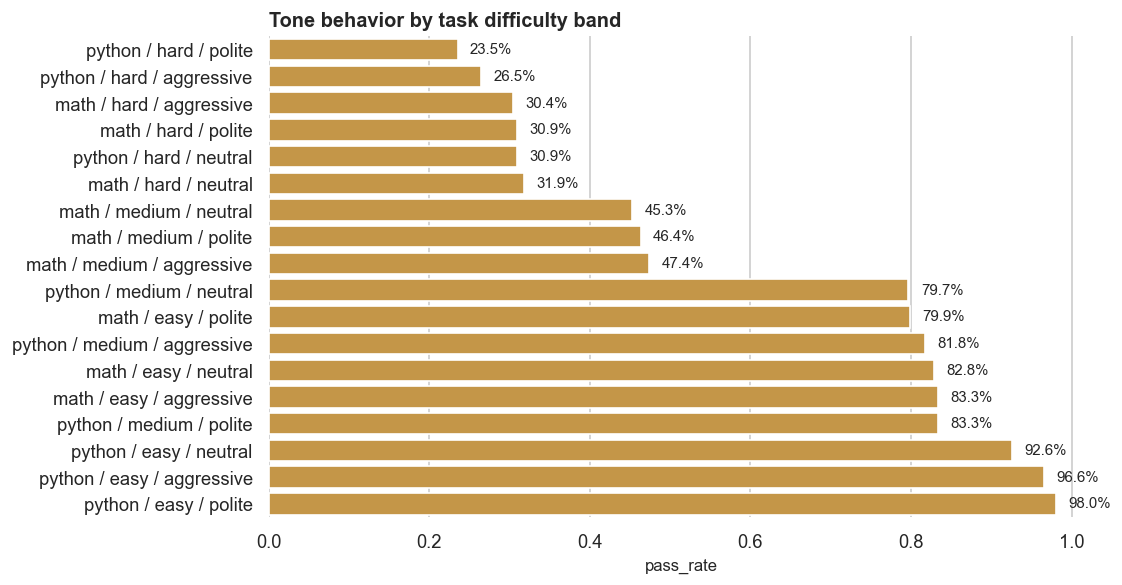

In [28]:

base_perf = df.groupby(['kind','task_id']).agg(base_pass_rate=('passed','mean'), base_tests_fraction=('tests_fraction','mean')).reset_index()
base_perf['difficulty_source'] = base_perf.base_tests_fraction.fillna(base_perf.base_pass_rate)
parts = []
for kind_name, sub in base_perf.groupby('kind'):
    tmp = sub.copy()
    tmp['difficulty_band'] = pd.qcut(tmp.difficulty_source.rank(method='first'), q=3, labels=['hard','medium','easy'])
    parts.append(tmp[['kind','task_id','difficulty_band']])
difficulty = pd.concat(parts, ignore_index=True)
df = df.merge(difficulty, on=['kind','task_id'], how='left', suffixes=('', '_new'))
if 'difficulty_band_new' in df:
    df['difficulty_band'] = df['difficulty_band'].fillna(df['difficulty_band_new'])
    df = df.drop(columns=['difficulty_band_new'])

diff_tone = df.groupby(['kind','difficulty_band','tone'], observed=False).agg(n=('passed','size'), pass_rate=('passed','mean'), tests_fraction=('tests_fraction','mean'), mean_completion_tokens=('completion_tokens','mean'), median_duration=('duration_seconds','median')).reset_index()
display(diff_tone)
plot = diff_tone.assign(label=diff_tone.kind.astype(str)+' / '+diff_tone.difficulty_band.astype(str)+' / '+diff_tone.tone.astype(str)).sort_values('pass_rate')
hbar(plot, 'pass_rate', 'label', 'Tone behavior by task difficulty band', color='#d89b34', height_per_row=.28)


## 18. Behavior-Control Models

In [29]:

def fit_lpm(data, outcome, controls):
    work = data[[outcome,'tone','role_binary','format','model_slug','kind','task_id', *controls]].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return pd.DataFrame(), 0
    y = work[outcome].astype(float).to_numpy()
    X = pd.get_dummies(work[['tone','role_binary','format','model_slug','kind','task_id', *controls]], drop_first=True, dtype=float)
    X.insert(0, 'Intercept', 1.0)
    beta, *_ = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
    pred = X.to_numpy() @ beta
    resid = y - pred
    dof = max(len(y) - X.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(X.to_numpy().T @ X.to_numpy())
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))
    out = pd.DataFrame({'term':X.columns, 'coef':beta, 'std_err':se, 'abs_coef':np.abs(beta), 'nobs':len(y)})
    return out, len(y)

df['passed_float'] = df.passed.astype(float)
df['log_completion_tokens'] = np.log1p(df.completion_tokens)
df['log_duration_seconds'] = np.log1p(df.duration_seconds)
control_sets = {
    'M0_prompt_model_task_fe': [],
    'M1_length': ['log_completion_tokens'],
    'M2_response_shape': ['extraction_failed'],
    'M3_runtime': ['log_duration_seconds'],
    'M4_all_behavior_controls': ['log_completion_tokens','extraction_failed','log_duration_seconds'],
}
rows=[]
for outcome in ['passed_float','tests_fraction']:
    for spec, controls in control_sets.items():
        res, nobs = fit_lpm(df, outcome, controls)
        if not res.empty:
            res['outcome'] = outcome
            res['model_spec'] = spec
            rows.append(res)
control_models = pd.concat(rows, ignore_index=True)
focus = control_models[control_models.term.str.contains('tone_|role_binary_|format_|log_completion|extraction_failed|log_duration', regex=True)].copy()
display(focus.sort_values(['outcome','model_spec','term'])[['outcome','model_spec','term','coef','std_err','nobs']])


,outcome,model_spec,term,coef,std_err,nobs
4,passed_float,M0_prompt_model_task_fe,format_plaintext,-0.009167,0.014916,3600
5,passed_float,M0_prompt_model_task_fe,format_xml,0.003333,0.014916,3600
3,passed_float,M0_prompt_model_task_fe,role_binary_role,-0.018889,0.012179,3600
1,passed_float,M0_prompt_model_task_fe,tone_neutral,-0.004167,0.014916,3600
2,passed_float,M0_prompt_model_task_fe,tone_polite,-0.006667,0.014916,3600
...,...,...,...,...,...,...
769,tests_fraction,M4_all_behavior_controls,log_completion_tokens,0.125543,0.005753,1800
771,tests_fraction,M4_all_behavior_controls,log_duration_seconds,0.011831,0.007525,1800
774,tests_fraction,M4_all_behavior_controls,role_binary_role,-0.031164,0.013127,1800
772,tests_fraction,M4_all_behavior_controls,tone_neutral,0.012801,0.016091,1800


## 19. Pooled Prompt Sensitivity And Behavior Controls

**Raw pooled prompt sensitivity across all task kinds**

,group,factor,baseline,level,baseline_n,n,baseline_pass_rate,pass_rate,delta_pp,p_value,completion_delta,duration_delta
3,all_task_kinds,format,plaintext,json,1200,1200,0.598333,0.607500,0.916667,0.646306,-69.205833,-1.757654
4,all_task_kinds,format,plaintext,xml,1200,1200,0.598333,0.610833,1.250000,0.531168,-66.425000,-1.410351
2,all_task_kinds,role_binary,no role,role,1800,1800,0.615000,0.596111,-1.888889,0.246267,36.149444,-0.797433
0,all_task_kinds,tone,neutral,aggressive,1200,1200,0.605000,0.609167,0.416667,0.834469,144.909167,0.837814
1,all_task_kinds,tone,neutral,polite,1200,1200,0.605000,0.602500,-0.250000,0.900366,45.442500,0.313391


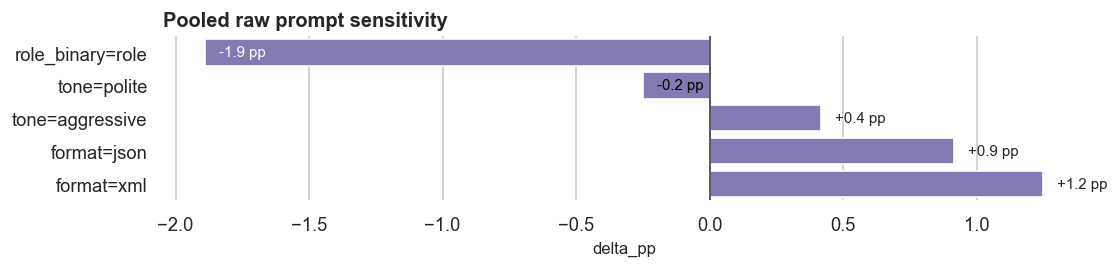

**Behavior-controlled pooled prompt sensitivity**

,group,term,coef_pp,std_err_pp,p_value,nobs,controls,fixed_effects
6,all_task_kinds,log_completion_tokens,15.229022,0.408736,7.626454e-304,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
5,all_task_kinds,format_xml_vs_plaintext,2.896592,1.243578,1.984634e-02,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
7,all_task_kinds,log_duration_seconds,-1.223321,0.601895,4.210807e-02,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
3,all_task_kinds,role_vs_no_role,-2.029400,1.014794,4.552020e-02,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
4,all_task_kinds,format_json_vs_plaintext,1.714772,1.243303,1.678309e-01,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
1,all_task_kinds,tone_aggressive_vs_neutral,-1.618779,1.243663,1.930454e-01,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"
2,all_task_kinds,tone_polite_vs_neutral,-0.840174,1.242670,4.989749e-01,3600,"log_completion_tokens, log_duration_seconds","model_slug, task_id, kind"


In [30]:

def prompt_raw_sensitivity(data, group_label='all'):
    baselines = {'tone':'neutral', 'role_binary':'no role', 'format':'plaintext'}
    records = []
    for factor, baseline in baselines.items():
        base = data[data[factor].eq(baseline)]
        if base.empty:
            continue
        for level, items in data.groupby(factor):
            if level == baseline:
                continue
            p_value = raw_two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items)) if 'raw_two_prop_p' in globals() else two_prop_p(base.passed.sum(), len(base), items.passed.sum(), len(items))
            records.append({
                'group': group_label,
                'factor': factor,
                'baseline': baseline,
                'level': level,
                'baseline_n': len(base),
                'n': len(items),
                'baseline_pass_rate': base.passed.mean(),
                'pass_rate': items.passed.mean(),
                'delta_pp': 100*(items.passed.mean() - base.passed.mean()),
                'p_value': p_value,
                'completion_delta': items.completion_tokens.mean() - base.completion_tokens.mean(),
                'duration_delta': items.duration_seconds.mean() - base.duration_seconds.mean(),
            })
    out = pd.DataFrame(records)
    return out

def prepare_behavior_frame(data):
    work = data.copy()
    work['passed_float'] = work.passed.astype(float)
    work['log_completion_tokens'] = np.log1p(pd.to_numeric(work.completion_tokens, errors='coerce').fillna(0))
    work['log_duration_seconds'] = np.log1p(pd.to_numeric(work.duration_seconds, errors='coerce').fillna(0))
    work['empty_response_control'] = work.empty_response.astype(float) if 'empty_response' in work else 0.0
    if 'extraction_failed' not in work:
        if 'extracted_code' in work:
            code_missing = work.extracted_code.fillna('').astype(str).str.strip().eq('')
            work['extraction_failed'] = np.where(work.kind.eq('code'), code_missing, False).astype(float)
        else:
            work['extraction_failed'] = 0.0
    work['extraction_failed'] = pd.to_numeric(work.extraction_failed, errors='coerce').fillna(0).astype(float)
    if 'api_error' in work:
        work['api_error_control'] = work.api_error.astype(float)
    else:
        work['api_error_control'] = 0.0
    return work

def controlled_prompt_model(data, group_label='all', include_kind=True):
    model_col = 'model_short' if 'model_short' in data.columns else 'model_slug'
    task_col = 'base_task_id' if 'base_task_id' in data.columns else 'task_id'
    work = prepare_behavior_frame(data)
    work['tone_aggressive_vs_neutral'] = work.tone.eq('aggressive').astype(float)
    work['tone_polite_vs_neutral'] = work.tone.eq('polite').astype(float)
    work['role_vs_no_role'] = work.role_binary.eq('role').astype(float)
    work['format_json_vs_plaintext'] = work.format.eq('json').astype(float)
    work['format_xml_vs_plaintext'] = work.format.eq('xml').astype(float)
    prompt_cols = ['tone_aggressive_vs_neutral','tone_polite_vs_neutral','role_vs_no_role','format_json_vs_plaintext','format_xml_vs_plaintext']
    behavior_cols = ['log_completion_tokens','log_duration_seconds','empty_response_control','extraction_failed','api_error_control']
    behavior_cols = [c for c in behavior_cols if c in work and work[c].nunique(dropna=True) > 1]
    fe_cols = [model_col, task_col] + (['kind'] if include_kind and work.kind.nunique() > 1 else [])
    needed = ['passed_float', *prompt_cols, *behavior_cols, *fe_cols]
    work = work[needed].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return pd.DataFrame()
    X = work[prompt_cols + behavior_cols].astype(float).copy()
    for col in fe_cols:
        dummies = pd.get_dummies(work[col].astype(str), prefix=col, drop_first=True, dtype=float)
        X = pd.concat([X, dummies], axis=1)
    X.insert(0, 'Intercept', 1.0)
    y = work.passed_float.to_numpy(dtype=float)
    Xv = X.to_numpy(dtype=float)
    beta, *_ = np.linalg.lstsq(Xv, y, rcond=None)
    pred = Xv @ beta
    resid = y - pred
    dof = max(len(y) - Xv.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(Xv.T @ Xv)
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))
    rows = pd.DataFrame({'term':X.columns, 'coef':beta, 'std_err':se})
    rows = rows[rows.term.isin(prompt_cols + behavior_cols)].copy()
    rows['group'] = group_label
    rows['coef_pp'] = 100 * rows.coef
    rows['std_err_pp'] = 100 * rows.std_err
    rows['p_value'] = [math.erfc(abs(c/s) / math.sqrt(2)) if s > 0 else 1.0 for c, s in zip(rows.coef, rows.std_err)]
    rows['nobs'] = len(y)
    rows['controls'] = ', '.join(behavior_cols) if behavior_cols else 'none'
    rows['fixed_effects'] = ', '.join(fe_cols)
    return rows[['group','term','coef_pp','std_err_pp','p_value','nobs','controls','fixed_effects']]

pooled_raw = prompt_raw_sensitivity(df, 'all_task_kinds')
display(Markdown('**Raw pooled prompt sensitivity across all task kinds**'))
display(pooled_raw.sort_values(['factor','level']))
if not pooled_raw.empty:
    pooled_raw_plot = pooled_raw.assign(label=pooled_raw.factor + '=' + pooled_raw.level).sort_values('delta_pp')
    hbar(pooled_raw_plot, 'delta_pp', 'label', 'Pooled raw prompt sensitivity', fmt='{:+.1f} pp', color='#7c6fbd', xline=0, height_per_row=.36)

pooled_controlled = controlled_prompt_model(df, 'all_task_kinds', include_kind=True)
display(Markdown('**Behavior-controlled pooled prompt sensitivity**'))
display(pooled_controlled.sort_values('p_value'))


## 20. Task-Kind Prompt Sensitivity And Behavior Controls

**Raw prompt sensitivity by task kind**

,group,factor,baseline,level,baseline_n,n,baseline_pass_rate,pass_rate,delta_pp,p_value,completion_delta,duration_delta
3,math,format,plaintext,json,600,600,0.545000,0.531667,-1.333333,0.643190,-33.436667,-1.960827
4,math,format,plaintext,xml,600,600,0.545000,0.521667,-2.333333,0.417887,-55.378333,-1.705222
2,math,role_binary,no role,role,900,900,0.546667,0.518889,-2.777778,0.237582,82.810000,0.473353
0,math,tone,neutral,aggressive,600,600,0.535000,0.538333,0.333333,0.907825,163.296667,0.952783
1,math,tone,neutral,polite,600,600,0.535000,0.525000,-1.000000,0.728565,79.613333,-0.402102
8,python,format,plaintext,json,600,600,0.651667,0.683333,3.166667,0.244328,-104.975000,-1.554482
9,python,format,plaintext,xml,600,600,0.651667,0.700000,4.833333,0.073686,-77.471667,-1.115480
7,python,role_binary,no role,role,900,900,0.683333,0.673333,-1.000000,0.649734,-10.511111,-2.068220
5,python,tone,neutral,aggressive,600,600,0.675000,0.680000,0.500000,0.853015,126.521667,0.722845
6,python,tone,neutral,polite,600,600,0.675000,0.680000,0.500000,0.853015,11.271667,1.028883


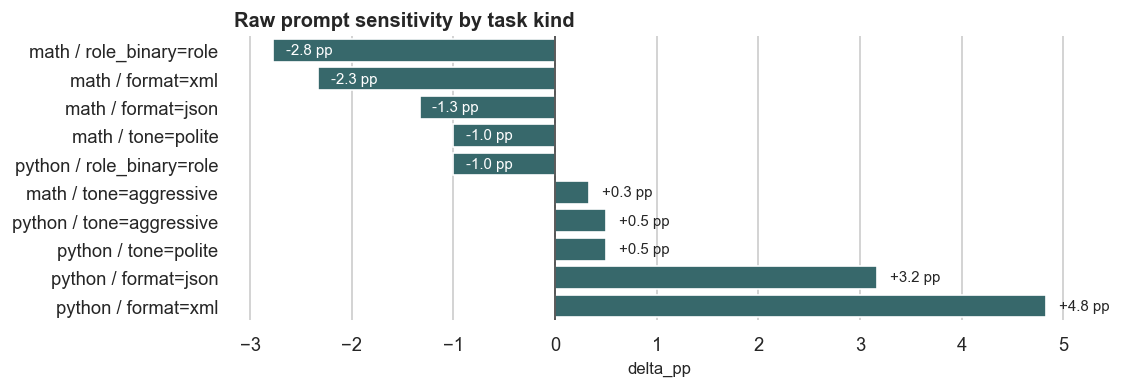

**Behavior-controlled prompt sensitivity by task kind**

,group,term,coef_pp,std_err_pp,p_value,nobs,controls,fixed_effects
5,math,log_completion_tokens,12.554285,0.575152,1.264573e-105,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
2,math,role_vs_no_role,-3.116406,1.312308,1.756079e-02,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
6,math,log_duration_seconds,1.183105,0.752296,1.157977e-01,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
0,math,tone_aggressive_vs_neutral,-1.280097,1.608599,4.261577e-01,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
1,math,tone_polite_vs_neutral,-1.124992,1.607148,4.839319e-01,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
3,math,format_json_vs_plaintext,-0.554318,1.608585,7.303953e-01,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
4,math,format_xml_vs_plaintext,-0.018090,1.609582,9.910330e-01,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
12,python,log_completion_tokens,13.594694,1.335444,2.437918e-24,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
11,python,format_xml_vs_plaintext,5.431626,1.877280,3.811586e-03,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"
13,python,log_duration_seconds,-2.574416,0.998370,9.919585e-03,1800,"log_completion_tokens, log_duration_seconds","model_slug, task_id"


In [31]:

raw_parts = []
controlled_parts = []
for kind_name, sub in df.groupby('kind'):
    raw_parts.append(prompt_raw_sensitivity(sub, kind_name))
    controlled_parts.append(controlled_prompt_model(sub, kind_name, include_kind=False))

kind_raw = pd.concat(raw_parts, ignore_index=True) if raw_parts else pd.DataFrame()
kind_controlled = pd.concat(controlled_parts, ignore_index=True) if controlled_parts else pd.DataFrame()

display(Markdown('**Raw prompt sensitivity by task kind**'))
display(kind_raw.sort_values(['group','factor','level']))
if not kind_raw.empty:
    plot = kind_raw.assign(label=kind_raw.group + ' / ' + kind_raw.factor + '=' + kind_raw.level).sort_values('delta_pp')
    hbar(plot, 'delta_pp', 'label', 'Raw prompt sensitivity by task kind', fmt='{:+.1f} pp', color='#2f6f73', xline=0, height_per_row=.34)

display(Markdown('**Behavior-controlled prompt sensitivity by task kind**'))
display(kind_controlled.sort_values(['group','p_value']))


## 21. Mediation Analysis: How Output Behavior Explains Prompt Effects

This section tests whether prompt effects on pass rate are mediated by three output-behavior variables:
- **Verbosity**: `log(completion_tokens)` — longer responses may indicate more explanation.
- **Result-only compliance**: `result_only` flag — whether the model outputs only the result (code for Python tasks, final answer for math tasks) without extra explanation text.
- **Duration**: `log(duration_seconds)` — response latency as an external behavioral measure.

We test all prompt factors (tone, role framing, format) across both task kinds.

In [ ]:

def fit_lpm_mediation(data, outcome_col, regressor_cols, fe_cols):
    needed = [outcome_col] + regressor_cols + fe_cols
    work = data[needed].replace([np.inf, -np.inf], np.nan).dropna()
    if work.empty:
        return {}
    y = work[outcome_col].astype(float).to_numpy()
    X = work[regressor_cols].astype(float).copy()
    for col in fe_cols:
        dummies = pd.get_dummies(work[col].astype(str), prefix=col, drop_first=True, dtype=float)
        X = pd.concat([X, dummies], axis=1)
    X.insert(0, 'Intercept', 1.0)
    Xv = X.to_numpy(dtype=float)
    beta, *_ = np.linalg.lstsq(Xv, y, rcond=None)
    pred = Xv @ beta
    resid = y - pred
    dof = max(len(y) - Xv.shape[1], 1)
    sigma2 = float((resid @ resid) / dof)
    xtx_inv = np.linalg.pinv(Xv.T @ Xv)
    se = np.sqrt(np.clip(np.diag(xtx_inv) * sigma2, 0, np.inf))
    result = {}
    for term, b, s in zip(X.columns, beta, se):
        if term in regressor_cols:
            p = math.erfc(abs(b / s) / math.sqrt(2)) if s > 0 else 1.0
            result[term] = {'coef': b, 'coef_pp': 100 * b, 'std_err': s, 'std_err_pp': 100 * s, 'p_value': p, 'nobs': len(y)}
    return result

df['log_completion_tokens'] = np.log1p(df['completion_tokens'])
df['log_duration'] = np.log1p(df['duration_seconds'])
df['result_only'] = 0
code_mask = df.kind.eq('python')
math_mask = df.kind.eq('math')
df.loc[code_mask, 'result_only'] = (df.loc[code_mask, 'response_text'].fillna('').str.len() < 2000).astype(int)
df.loc[math_mask, 'result_only'] = (df.loc[math_mask, 'response_text'].fillna('').str.len() < 50).astype(int)
df['passed_float'] = df['passed'].astype(float)
df['tone_aggressive'] = df['tone'].eq('aggressive').astype(float)
df['tone_polite'] = df['tone'].eq('polite').astype(float)
df['role_vs_no_role'] = df['role_binary'].eq('role').astype(float)
df['format_json'] = df['format'].eq('json').astype(float)
df['format_xml'] = df['format'].eq('xml').astype(float)

prompt_cols = ['tone_aggressive', 'tone_polite', 'role_vs_no_role', 'format_json', 'format_xml']
fe_cols = ['model_slug', 'task_id']

# Step 1: All factors affect all mediators
display(Markdown('### Step 1: Effect of each factor on mediators'))
for kind_name in sorted(df.kind.unique()):
    sub = df[df.kind.eq(kind_name)]
    display(Markdown(f'**{kind_name} tasks**'))
    step1_rows = []
    for mediator_name, mediator_col in [('log(tokens)', 'log_completion_tokens'), ('result_only', 'result_only'), ('log(duration)', 'log_duration')]:
        res = fit_lpm_mediation(sub, mediator_col, prompt_cols, fe_cols)
        for term in prompt_cols:
            if term in res:
                r = res[term]
                step1_rows.append({'mediator': mediator_name, 'factor': term, 'coef_pp': r['coef_pp'], 'p_value': r['p_value'], 'significant': r['p_value'] < 0.05})
    display(pd.DataFrame(step1_rows))

# Steps 2-4: Mediation with multiple control specifications
display(Markdown('### Steps 2-4: Mediation decomposition'))
specs = {
    'total': [],
    '+tokens': ['log_completion_tokens'],
    '+res_only': ['result_only'],
    '+duration': ['log_duration'],
    '+tok+ro': ['log_completion_tokens', 'result_only'],
    '+tok+dur': ['log_completion_tokens', 'log_duration'],
    '+ro+dur': ['result_only', 'log_duration'],
    '+all3': ['log_completion_tokens', 'result_only', 'log_duration'],
}

for kind_name in sorted(df.kind.unique()):
    sub = df[df.kind.eq(kind_name)].copy()
    display(Markdown(f'**{kind_name} tasks**'))
    total_res = fit_lpm_mediation(sub, 'passed_float', prompt_cols, fe_cols)
    rows = []
    for term in prompt_cols:
        if term not in total_res: continue
        tc = total_res[term]['coef']
        row = {'factor': term, 'total_pp': total_res[term]['coef_pp'], 'total_p': total_res[term]['p_value']}
        for spec_name, ctrl_cols in specs.items():
            if spec_name == 'total': continue
            res = fit_lpm_mediation(sub, 'passed_float', prompt_cols + ctrl_cols, fe_cols)
            if term in res:
                cc = res[term]['coef']
                indirect = tc - cc
                prop = indirect / tc if abs(tc) > 1e-10 else np.nan
                row[f'{spec_name}_pp'] = res[term]['coef_pp']
                row[f'{spec_name}_prop'] = prop
        rows.append(row)
    display(pd.DataFrame(rows))
